In [1]:

import pandas as pd

data = {
    "Order_ID": [101, 102, 103, 104, 105, 106],
    "Product": ["Laptop", "Mobile", "Tablet", "Laptop", "Mobile", "Tablet"],
    "Category": ["Computers", "Electronics", "Electronics",
                 "Computers", "Electronics", "Electronics"],
    "Sales": [50000, 30000, 20000, 55000, None, 22000],
    "Quantity": [5, 10, 8, 6, 12, 9]
}

df = pd.DataFrame(data)

print(df)


   Order_ID Product     Category    Sales  Quantity
0       101  Laptop    Computers  50000.0         5
1       102  Mobile  Electronics  30000.0        10
2       103  Tablet  Electronics  20000.0         8
3       104  Laptop    Computers  55000.0         6
4       105  Mobile  Electronics      NaN        12
5       106  Tablet  Electronics  22000.0         9


In [2]:

# First five rows
print(df.head())

# Number of rows and columns
print(df.shape)

# Column information and data types
df.info()

# Missing values in each column
print(df.isnull().sum())

# Summary statistics
print(df.describe())


   Order_ID Product     Category    Sales  Quantity
0       101  Laptop    Computers  50000.0         5
1       102  Mobile  Electronics  30000.0        10
2       103  Tablet  Electronics  20000.0         8
3       104  Laptop    Computers  55000.0         6
4       105  Mobile  Electronics      NaN        12
(6, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Order_ID  6 non-null      int64  
 1   Product   6 non-null      object 
 2   Category  6 non-null      object 
 3   Sales     5 non-null      float64
 4   Quantity  6 non-null      int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 372.0+ bytes
Order_ID    0
Product     0
Category    0
Sales       1
Quantity    0
dtype: int64
         Order_ID         Sales   Quantity
count    6.000000      5.000000   6.000000
mean   103.500000  35400.000000   8.333333
std      1.870829  16149.3033

In [3]:

print(df.isnull().sum())


Order_ID    0
Product     0
Category    0
Sales       1
Quantity    0
dtype: int64


In [4]:

median_sales = df["Sales"].median()

print("Median Sales:", median_sales)


Median Sales: 30000.0


In [5]:

df_clean = df.copy()

df_clean["Sales"] = df_clean["Sales"].fillna(
    median_sales
)

print(df_clean)


   Order_ID Product     Category    Sales  Quantity
0       101  Laptop    Computers  50000.0         5
1       102  Mobile  Electronics  30000.0        10
2       103  Tablet  Electronics  20000.0         8
3       104  Laptop    Computers  55000.0         6
4       105  Mobile  Electronics  30000.0        12
5       106  Tablet  Electronics  22000.0         9


In [6]:

print("Duplicate rows:", df_clean.duplicated().sum())

print("Duplicate Order IDs:",
      df_clean["Order_ID"].duplicated().sum())


Duplicate rows: 0
Duplicate Order IDs: 0


In [7]:

print(df_clean.isnull().sum())
print(df_clean.info())


Order_ID    0
Product     0
Category    0
Sales       0
Quantity    0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Order_ID  6 non-null      int64  
 1   Product   6 non-null      object 
 2   Category  6 non-null      object 
 3   Sales     6 non-null      float64
 4   Quantity  6 non-null      int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 372.0+ bytes
None


In [8]:

total_revenue = df_clean["Sales"].sum()
total_quantity = df_clean["Quantity"].sum()
total_orders = df_clean["Order_ID"].nunique()

print("Total Revenue:", total_revenue)
print("Total Quantity:", total_quantity)
print("Total Orders:", total_orders)


Total Revenue: 207000.0
Total Quantity: 50
Total Orders: 6


In [9]:

product_revenue = (
    df_clean.groupby("Product")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(product_revenue)


Product
Laptop    105000.0
Mobile     60000.0
Tablet     42000.0
Name: Sales, dtype: float64


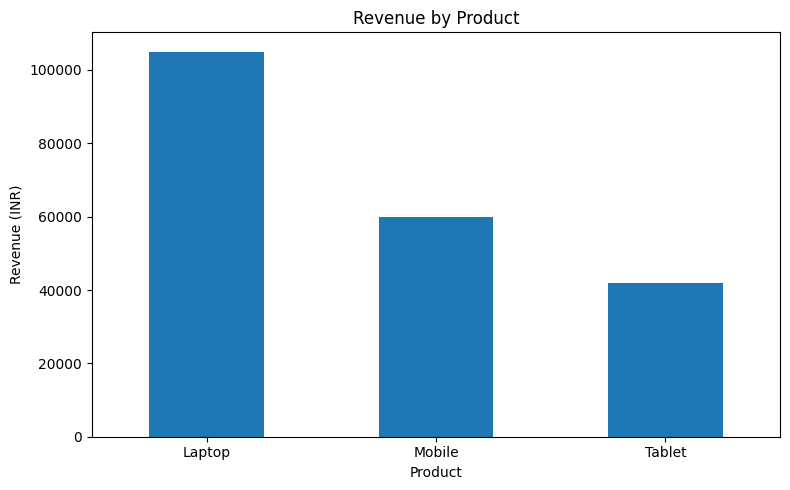

In [10]:

import matplotlib.pyplot as plt

product_revenue.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [11]:
category_revenue = (
    df_clean.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(category_revenue)

Category
Computers      105000.0
Electronics    102000.0
Name: Sales, dtype: float64


In [12]:

total_revenue = df_clean["Sales"].sum()
total_orders = df_clean["Order_ID"].nunique()

aov = total_revenue / total_orders

print("Average Order Value:", round(aov, 2))


Average Order Value: 34500.0


In [13]:

product_revenue = df_clean.groupby("Product")["Sales"].sum()

contribution = (
    product_revenue / total_revenue
) * 100

print(contribution.round(2))


Product
Laptop    50.72
Mobile    28.99
Tablet    20.29
Name: Sales, dtype: float64


In [14]:

product_summary = df_clean.groupby("Product").agg(
    Total_Revenue=("Sales", "sum"),
    Total_Quantity=("Quantity", "sum")
)

product_summary["Revenue_Per_Unit"] = (
    product_summary["Total_Revenue"] /
    product_summary["Total_Quantity"]
)

print(product_summary.round(2))


         Total_Revenue  Total_Quantity  Revenue_Per_Unit
Product                                                 
Laptop        105000.0              11           9545.45
Mobile         60000.0              22           2727.27
Tablet         42000.0              17           2470.59


In [15]:

df_clean.to_csv(
    "retail_sales_cleaned.csv",
    index=False
)

from google.colab import files
files.download("retail_sales_cleaned.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>